# Eval experiments
Compare runs logged in `experiments.csv` and drill into per-file predictions.

In [1]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath("__file__"))  # run from eval/
exp = pd.read_csv(os.path.join(HERE, "experiments.csv"))
exp

,scored_at,run,split,key,n,backend,model,prompt_sha1,max_pixels,crop_top,...,vlm_company,vlm_location,vlm_job_id,vlm_pay,halluc_pct,vlm_p50_s,vlm_p95_s,gain_pts,mcnemar_p,verdict
0,2026-10-25T21:39:30,q25vl3b,dev,png,19,local,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,20171485d1,1048576,1.0,...,31.6,78.9,36.8,36.8,40.7,6.22,7.20,10.5,0.500,NOT_MET
1,2026-10-25T21:57:24,dev_v1_prompt,dev,png,19,local,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,31.6,78.9,42.1,42.1,35.2,5.51,5.75,5.3,1.000,NOT_MET
2,2026-10-25T22:10:39,dev_px1m,dev,png,19,local,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,31.6,78.9,42.1,42.1,35.2,5.60,6.48,5.3,1.000,NOT_MET
3,2026-10-25T23:26:09,q25vl3b_v2,dev,png,19,local,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,31.6,78.9,42.1,42.1,35.2,7.23,9.23,5.3,1.000,NOT_MET
4,2026-10-25T23:26:09,q25vl7b,dev,png,19,local,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,52.6,73.7,89.5,47.4,31.2,13.34,17.40,21.1,0.125,NOT_MET
5,2026-10-25T23:26:09,q3vl8b,dev,png,19,local,mlx-community/Qwen3-VL-8B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,63.2,63.2,89.5,42.1,23.1,8.36,11.80,26.3,0.062,NOT_MET
6,2026-10-25T23:26:09,q3vl8b_or,dev,png,19,paid,qwen/qwen3-vl-8b-instruct,4fc8796fa6,1048576,1.0,...,42.1,47.4,78.9,31.6,27.1,1.99,60.48,15.8,0.250,NOT_MET
7,2026-10-25T23:27:09,q25vl3b_v2,test,png,62,local,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,41.9,72.6,24.2,19.4,44.8,7.36,8.07,3.2,0.500,NOT_MET
8,2026-10-25T23:27:09,q25vl7b,test,png,62,local,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,56.5,79.0,80.6,17.7,39.4,13.46,16.12,11.3,0.016,NOT_MET
9,2026-10-25T23:27:09,q3vl8b,test,png,62,local,mlx-community/Qwen3-VL-8B-Instruct-4bit,4fc8796fa6,1048576,1.0,...,51.6,75.8,83.9,19.4,29.0,8.85,12.01,11.3,0.016,NOT_MET


## Headline metrics per run

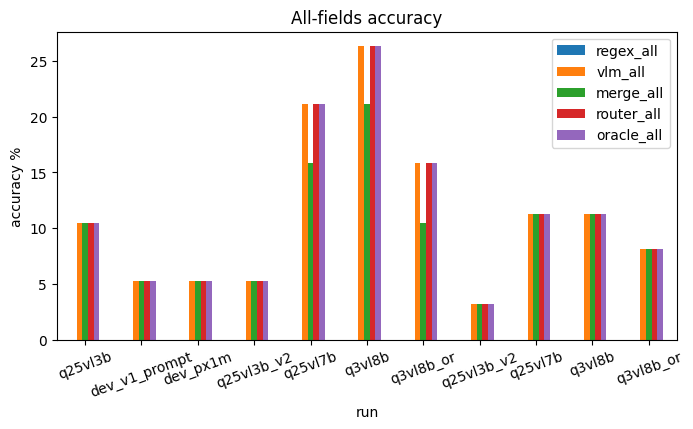

In [2]:
# Overall accuracy (%) for each pipeline stage, one bar group per run
exp.set_index("run")[["regex_all","vlm_all","merge_all","router_all","oracle_all"]].plot.bar(figsize=(8,4))
plt.ylabel("accuracy %"); plt.title("All-fields accuracy"); plt.xticks(rotation=20); plt.show()

## Per-field VLM accuracy

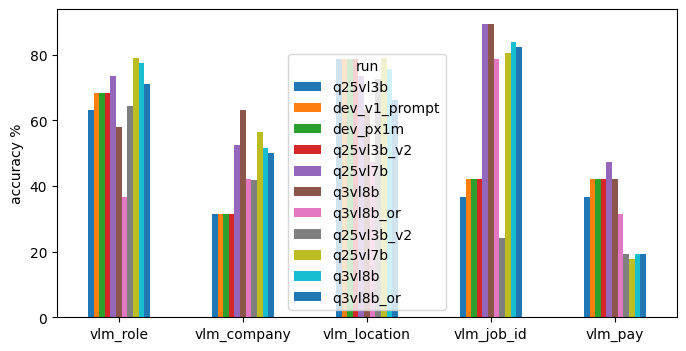

In [3]:
# VLM accuracy per field, one bar group per run
exp.set_index("run")[["vlm_role","vlm_company","vlm_location","vlm_job_id","vlm_pay"]].T.plot.bar(figsize=(8,4))
plt.ylabel("accuracy %"); plt.xticks(rotation=0); plt.show()

## Latency & hallucination

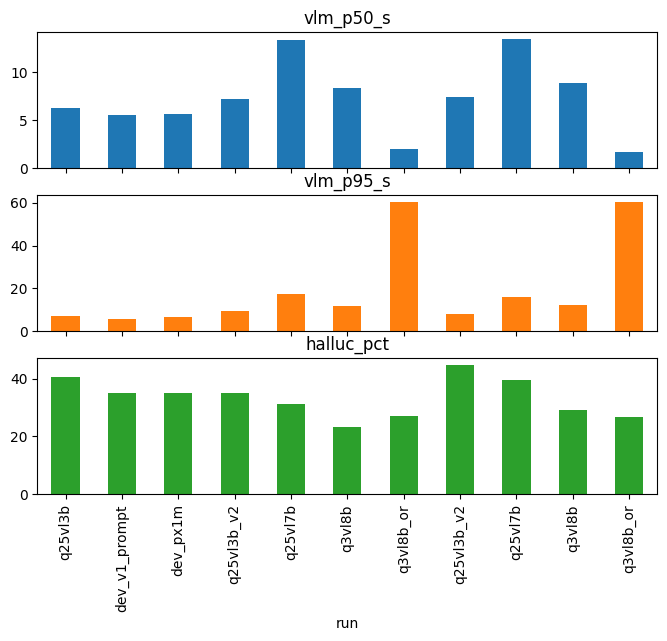

In [4]:
exp.set_index("run")[["vlm_p50_s","vlm_p95_s","halluc_pct"]].plot.bar(subplots=True, figsize=(8,6), legend=False)
plt.show()

## Config diff between runs
Shows only columns whose values differ.

In [5]:
cfg = exp.set_index("run").T
cfg[cfg.nunique(axis=1) > 1]

run,q25vl3b,dev_v1_prompt,dev_px1m,q25vl3b_v2,q25vl7b,q3vl8b,q3vl8b_or,q25vl3b_v2,q25vl7b,q3vl8b,q3vl8b_or
scored_at,2026-10-25T21:39:30,2026-10-25T21:57:24,2026-10-25T22:10:39,2026-10-25T23:26:09,2026-10-25T23:26:09,2026-10-25T23:26:09,2026-10-25T23:26:09,2026-10-25T23:27:09,2026-10-25T23:27:09,2026-10-25T23:27:09,2026-10-25T23:27:09
split,dev,dev,dev,dev,dev,dev,dev,test,test,test,test
n,19,19,19,19,19,19,19,62,62,62,62
backend,local,local,local,local,local,local,paid,local,local,local,paid
model,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,mlx-community/Qwen3-VL-8B-Instruct-4bit,qwen/qwen3-vl-8b-instruct,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,mlx-community/Qwen3-VL-8B-Instruct-4bit,qwen/qwen3-vl-8b-instruct
prompt_sha1,20171485d1,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6
note,baseline: original prompt (with example values...,"prompt v1: no examples, never-guess, exact-as-...","v1 prompt, upscale to ~1MP",frozen v1 dev check,frozen v1 dev check,frozen v1 dev check,frozen v1 dev check,frozen v1 final,frozen v1 final,frozen v1 final,frozen v1 final
vlm_all,10.5,5.3,5.3,5.3,21.1,26.3,15.8,3.2,11.3,11.3,8.1
merge_all,10.5,5.3,5.3,5.3,15.8,21.1,10.5,3.2,11.3,11.3,8.1
router_all,10.5,5.3,5.3,5.3,21.1,26.3,15.8,3.2,11.3,11.3,8.1


## Per-file predictions
Load a run's predictions and flag VLM fields not found in the OCR text.

In [6]:
def load_run(run):
    """Load predictions.jsonl for a run into a flat DataFrame (one row per file)."""
    rows = []
    for line in open(os.path.join(HERE, "runs", run, "predictions.jsonl")):
        r = json.loads(line)
        row = {"file": r["file"], "vlm_latency": r["vlm"]["latency_s"], "vlm_error": r["vlm"]["error"]}
        row.update({f"vlm_{k}": v for k, v in r["vlm"]["fields"].items()})
        row.update({f"regex_{k}": v for k, v in r["regex"]["fields"].items()})
        row.update({f"inocr_{k}": v for k, v in r["vlm_in_ocr"].items()})
        rows.append(row)
    return pd.DataFrame(rows)

run = exp["run"].iloc[-1]  # change to inspect another run
df = load_run(run)
df[["file","vlm_role","regex_role","vlm_company","vlm_location","vlm_job_id","vlm_pay"]]

AttributeError: 'NoneType' object has no attribute 'items'

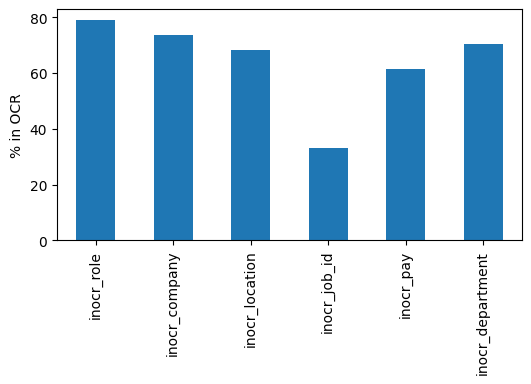

In [ ]:
# Share of VLM answers found in OCR text, per field (low = likely hallucination)
(df.filter(like="inocr_").mean()*100).plot.bar(figsize=(6,3)); plt.ylabel("% in OCR"); plt.show()

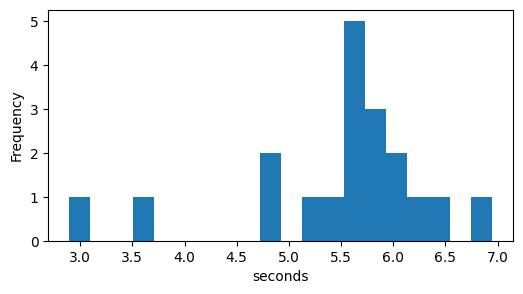

In [ ]:
# Latency distribution
df["vlm_latency"].plot.hist(bins=20, figsize=(6,3)); plt.xlabel("seconds"); plt.show()

## Compare two runs on the same files

In [ ]:
a, b = exp["run"].iloc[0], exp["run"].iloc[-1]
cmp = load_run(a).merge(load_run(b), on="file", suffixes=(f"_{a}", f"_{b}"))
# Show files where the VLM role answer changed
cmp[cmp[f"vlm_role_{a}"] != cmp[f"vlm_role_{b}"]][["file", f"vlm_role_{a}", f"vlm_role_{b}"]]

,file,vlm_role_q25vl3b,vlm_role_dev_px1m
0,JBATA-dev.png,Developer,JBATA - Developer
12,image copy 40.png,Software Developer,Software Engineer
